# Olist Customer Data Cleaning

Cleaning and restructuring the Olist customers table (99,441 order-level records) into one clean row per unique customer, with region and repeat-customer features.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd

## 2. Load the data

In [4]:
df = pd.read_csv("../data/raw/olist_customers_dataset.csv", dtype=str)
raw_rows = len(df)
print(df.shape)
df.head()

(99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  object
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: object(5)
memory usage: 3.8+ MB


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
count,99441,99441,99441,99441,99441
unique,99441,96096,14994,4119,27
top,274fa6071e5e17fe303b9748641082c8,8d50f5eadf50201ccdcedfb9e2ac8455,22790,sao paulo,SP
freq,1,17,142,15540,41746


## 3. Data quality checks

In [6]:
print(df.isnull().sum())
print("full duplicate rows:", df.duplicated().sum())
print("duplicate customer_id:", df["customer_id"].duplicated().sum())
print("duplicate customer_unique_id:", df["customer_unique_id"].duplicated().sum())

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
full duplicate rows: 0
duplicate customer_id: 0
duplicate customer_unique_id: 3345


In [7]:
print(df["customer_zip_code_prefix"].str.len().value_counts())
print("non digit zip codes:", df["customer_zip_code_prefix"].str.contains(r"\D").sum())
print("unique cities:", df["customer_city"].nunique())
print("unique states:", df["customer_state"].nunique())

customer_zip_code_prefix
5    99441
Name: count, dtype: int64
non digit zip codes: 0
unique cities: 4119
unique states: 27


## 4. Standardize text and validate fields

In [8]:
for col in df.columns:
    df[col] = df[col].str.strip()

df["customer_city"] = df["customer_city"].str.lower()
df["customer_state"] = df["customer_state"].str.upper()

In [9]:
df["customer_zip_code_prefix"] = df["customer_zip_code_prefix"].str.zfill(5)
invalid_zip = ~df["customer_zip_code_prefix"].str.fullmatch(r"\d{5}")
print("invalid zip codes:", invalid_zip.sum())

invalid zip codes: 0


In [10]:
import re
import unicodedata

def normalize_city(text):
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["customer_city"] = df["customer_city"].apply(normalize_city).str.title()
df["customer_city"].sample(10, random_state=1)

,customer_city
90678,Nova Friburgo
53288,Major Vieira
23486,Sorocaba
50028,Japeri
60525,Sao Paulo
83885,Feira De Santana
542,Sao Goncalo
78310,Rio De Janeiro
13580,Rondon Do Para
98420,Curitiba


In [11]:
valid_states = [
    "AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
    "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO",
]
invalid_states = ~df["customer_state"].isin(valid_states)
print("invalid states:", invalid_states.sum())

invalid states: 0


## 5. Add region

In [12]:
region_map = {
    "AC": "North", "AP": "North", "AM": "North", "PA": "North", "RO": "North", "RR": "North", "TO": "North",
    "AL": "Northeast", "BA": "Northeast", "CE": "Northeast", "MA": "Northeast", "PB": "Northeast",
    "PE": "Northeast", "PI": "Northeast", "RN": "Northeast", "SE": "Northeast",
    "DF": "Central-West", "GO": "Central-West", "MT": "Central-West", "MS": "Central-West",
    "ES": "Southeast", "MG": "Southeast", "RJ": "Southeast", "SP": "Southeast",
    "PR": "South", "RS": "South", "SC": "South",
}
df["region"] = df["customer_state"].map(region_map)
print(df["region"].value_counts(dropna=False))

region
Southeast       68266
South           14148
Northeast        9394
Central-West     5782
North            1851
Name: count, dtype: int64


## 6. Orders per customer

In [13]:
orders_per_customer = df.groupby("customer_unique_id").size().rename("orders_count")
df = df.merge(orders_per_customer, on="customer_unique_id", how="left")
print(df["orders_count"].value_counts().sort_index())
print("repeat customers:", (orders_per_customer > 1).sum())

orders_count
1     93099
2      5490
3       609
4       120
5        40
6        36
7        21
9         9
17       17
Name: count, dtype: int64
repeat customers: 2997


In [14]:
location_check = df.groupby("customer_unique_id").agg(
    cities=("customer_city", "nunique"),
    zips=("customer_zip_code_prefix", "nunique"),
)
print("customers with more than one city:", (location_check["cities"] > 1).sum())
print("customers with more than one zip:", (location_check["zips"] > 1).sum())

customers with more than one city: 122
customers with more than one zip: 250


## 7. Build the customer table

In [15]:
id_map = df[["customer_id", "customer_unique_id"]].copy()

customers = (
    df.drop_duplicates(subset="customer_unique_id", keep="first")
    .drop(columns="customer_id")
    .reset_index(drop=True)
)

customers["customer_type"] = np.where(customers["orders_count"] > 1, "Repeat", "One-time")

print(customers.shape)
customers.head()

(96096, 7)


,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,region,orders_count,customer_type
0,861eff4711a542e4b93843c6dd7febb0,14409,Franca,SP,Southeast,1,One-time
1,290c77bc529b7ac935b93aa66c333dc3,09790,Sao Bernardo Do Campo,SP,Southeast,1,One-time
2,060e732b5b29e8181a18229c7b0b2b5e,01151,Sao Paulo,SP,Southeast,1,One-time
3,259dac757896d24d7702b9acbbff3f3c,08775,Mogi Das Cruzes,SP,Southeast,1,One-time
4,345ecd01c38d18a9036ed96c73b8d066,13056,Campinas,SP,Southeast,1,One-time


## 8. Validation checks

In [16]:
checks = {
    "no_null_values": customers.isnull().sum().sum() == 0,
    "unique_customers": customers["customer_unique_id"].is_unique,
    "zip_has_5_digits": customers["customer_zip_code_prefix"].str.fullmatch(r"\d{5}").all(),
    "valid_states": customers["customer_state"].isin(valid_states).all(),
    "orders_count_positive": (customers["orders_count"] > 0).all(),
    "id_map_complete": len(id_map) == raw_rows,
}

for name, passed in checks.items():
    print(name, "PASSED" if passed else "FAILED")

assert all(checks.values())

no_null_values PASSED
unique_customers PASSED
zip_has_5_digits PASSED
valid_states PASSED
orders_count_positive PASSED
id_map_complete PASSED


In [17]:
summary = pd.DataFrame({
    "metric": ["rows", "unique customers", "repeat customers", "repeat rate %"],
    "value": [
        raw_rows,
        len(customers),
        int((customers["customer_type"] == "Repeat").sum()),
        round((customers["customer_type"] == "Repeat").mean() * 100, 2),
    ],
})
summary

,metric,value
0,rows,99441.00
1,unique customers,96096.00
2,repeat customers,2997.00
3,repeat rate %,3.12


## 9. Export to CSV and SQLite

In [18]:
import sqlite3

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../images", exist_ok=True)

customers.to_csv("../data/processed/customers_clean.csv", index=False)
id_map.to_csv("../data/processed/customer_id_map.csv", index=False)

with sqlite3.connect("../data/processed/customers.db") as conn:
    customers.to_sql("customers", conn, if_exists="replace", index=False)
    id_map.to_sql("customer_id_map", conn, if_exists="replace", index=False)

print(os.listdir("../data/processed"))

['customers_clean.csv', 'customers.db', 'customer_id_map.csv']


In [19]:
with sqlite3.connect("../data/processed/customers.db") as conn:
    result = pd.read_sql(
        "SELECT region, customer_type, COUNT(*) AS customers "
        "FROM customers GROUP BY region, customer_type ORDER BY customers DESC",
        conn,
    )
result

,region,customer_type,customers
0,Southeast,One-time,63761
1,South,One-time,13274
2,Northeast,One-time,8905
3,Central-West,One-time,5416
4,Southeast,Repeat,2129
5,North,One-time,1743
6,South,Repeat,414
7,Northeast,Repeat,228
8,Central-West,Repeat,176
9,North,Repeat,50


## 10. Visualizations

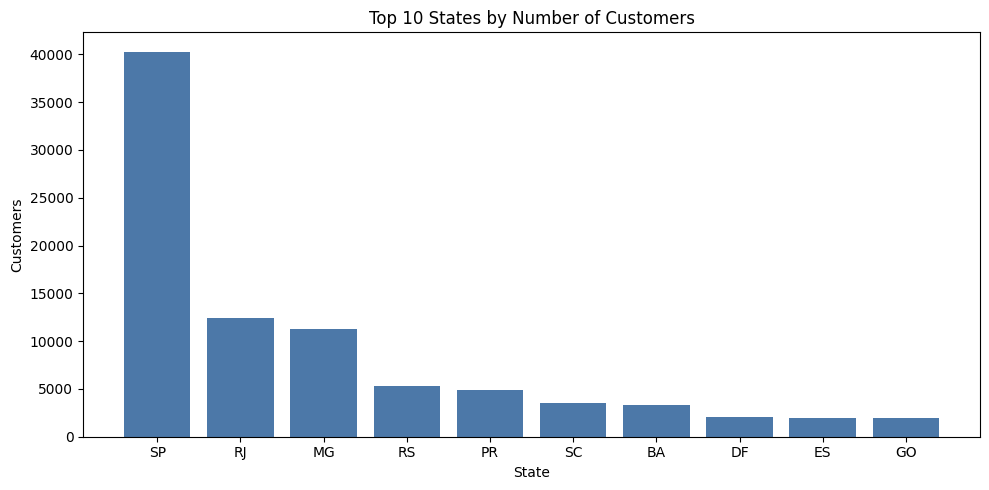

In [20]:
import matplotlib.pyplot as plt

state_counts = customers["customer_state"].value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.bar(state_counts.index, state_counts.values, color="#4C78A8")
plt.title("Top 10 States by Number of Customers")
plt.xlabel("State")
plt.ylabel("Customers")
plt.tight_layout()
plt.savefig("../images/customers_by_state.png", dpi=150)
plt.show()

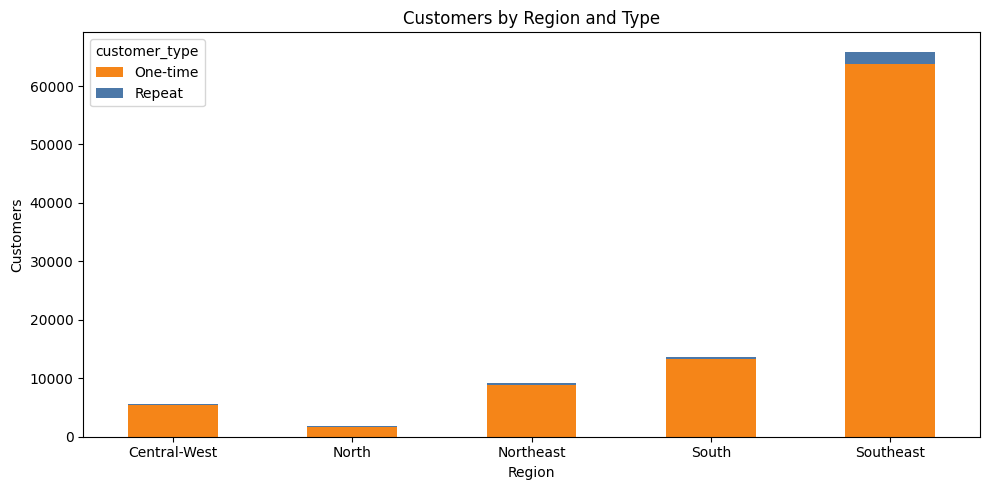

In [21]:
region_type = customers.groupby(["region", "customer_type"]).size().unstack(fill_value=0)

region_type.plot(kind="bar", stacked=True, figsize=(10, 5), color=["#F58518", "#4C78A8"])
plt.title("Customers by Region and Type")
plt.xlabel("Region")
plt.ylabel("Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/customers_by_region.png", dpi=150)
plt.show()

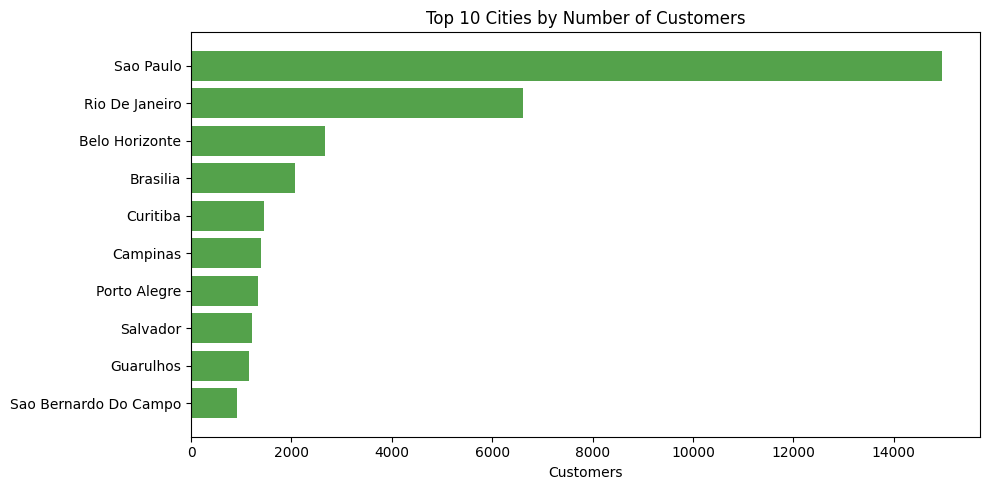

In [22]:
top_cities = customers["customer_city"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 5))
plt.barh(top_cities.index, top_cities.values, color="#54A24B")
plt.title("Top 10 Cities by Number of Customers")
plt.xlabel("Customers")
plt.tight_layout()
plt.savefig("../images/top_cities.png", dpi=150)
plt.show()